<span style="color:blue; font-size:14px; font-weight:bold;">
The Analysis is about turning orders, customers, producst, sales channels into insights that help 
selling more, spend less or keep cusomers longer
</span>

##### The analysis is used for Sales performances : Revenue trends, seasonality, average order value 
##### Customers analysis with customer lifetime value, spotting those likely to stop buying
##### Cohort and retention analysis , tracking whether customers acquired in a given month keep coming back
##### Funnel and conversion analysis finding where customers dropped off
##### Returns , measuring how discounts affect volume and margin...

<span style="color:green; font-size:22px; font-weight:bold;">
Explore the data....
</span>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import seaborn as sns
import arviz as az

data= pd.read_csv('/Users/jeanmiccheltia/Downloads/Ecommerce.csv', sep=";")
data.head(2)

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,...,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,...,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,...,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11


In [2]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_id                  138116 non-null  object 
 1   order_date                138116 non-null  object 
 2   order_time                138116 non-null  object 
 3   order_status              138116 non-null  object 
 4   sales_channel             138116 non-null  object 
 5   customer_id               138116 non-null  object 
 6   customer_name             138116 non-null  object 
 7   customer_age              138116 non-null  int64  
 8   gender                    138116 non-null  object 
 9   customer_segment          138116 non-null  object 
 10  customer_type             138116 non-null  object 
 11  customer_city             138116 non-null  object 
 12  customer_state            138116 non-null  object 
 13  customer_country          138116 non-null  o

In [3]:
data['return_reason'] = data['return_reason'].fillna('Kept')
data['campaign_name'] = data['campaign_name'].fillna('No Campaign')
data['coupon_code'] = data['coupon_code'].fillna('SAVE00')
data['return_status'] = data['return_status'].fillna('Kept')

In [4]:
data['estimated_delivery_days']= data['estimated_delivery_days'].fillna(data['estimated_delivery_days'].mean())
data['delivery_days'] = data['delivery_days'].fillna(data['delivery_days'].mean())

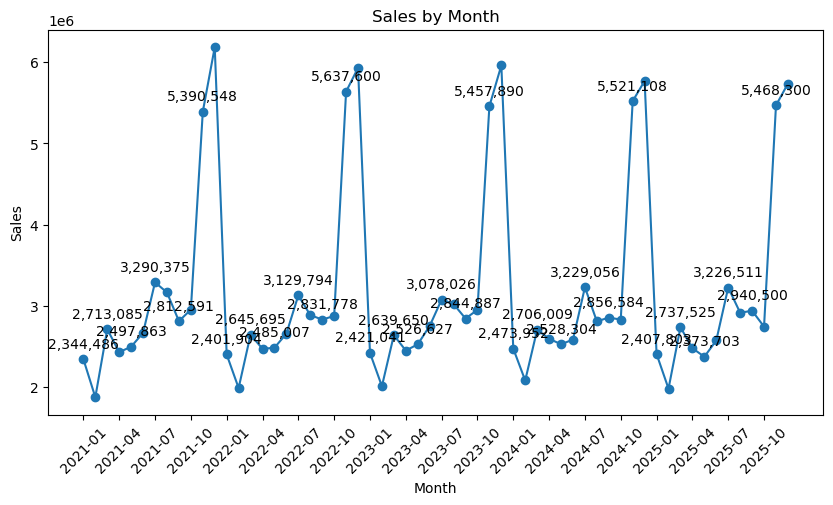

In [5]:
data['order_date'] = pd.to_datetime(data['order_date'])
data['month']      = data['order_date'].dt.to_period('M')

avg_order_value = (
    data
    .groupby("month")["gross_sales"]
    .mean()
)

orders_customer_month = (
    data
    .groupby(["month", "customer_id"])["order_id"]
    .nunique()
    .reset_index(name="number_of_orders")
)

avg_order_number = (
    orders_customer_month
    .groupby("month")["number_of_orders"]
    .mean()
)
Total_sales = (
    data
    .groupby("month")["gross_sales"]
    .sum()
)

x = Total_sales.index.astype(str)
y = Total_sales.values

fig, ax =plt.subplots(figsize=(10,5))

ax.plot(
    x,
    y,
    marker="o")
ax.set_xticks(x[::3])
ax.tick_params(axis="x", rotation=45)

for xi,yi in zip(x[::2], y[::2]):
    ax.annotate(
        f"{yi:,.0f}",
        (xi, yi),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center")

plt.title("Sales by Month")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.show()

A cyclical trend with peak around the end of the yearindicate that most sales occur by the end of the year

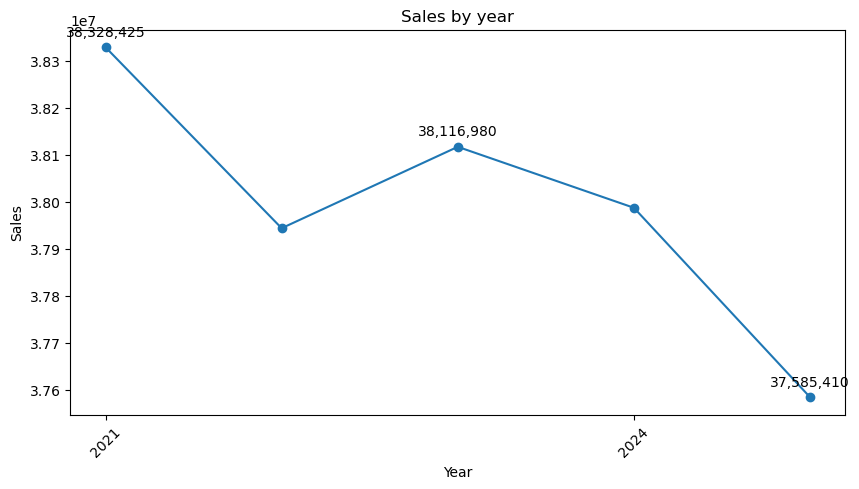

In [6]:
data['year'] = data['order_date'].dt.to_period('Y')
yearly_sales = (
    data
    .groupby("year")["gross_sales"]
    .sum()
)
x = yearly_sales.index.astype(str)
y = yearly_sales.values

fig, ax =plt.subplots(figsize=(10,5))

ax.plot(
    x,
    y,
    marker="o")
ax.set_xticks(x[::3])
ax.tick_params(axis="x", rotation=45)

for xi,yi in zip(x[::2], y[::2]):
    ax.annotate(
        f"{yi:,.0f}",
        (xi, yi),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center")

plt.title("Sales by year")
plt.xlabel("Year")
plt.ylabel("Sales")
plt.show()

The sales have been decreasing from 2023 until the end of the period 2025. Pointing to a likely change of customers habits from this period. 

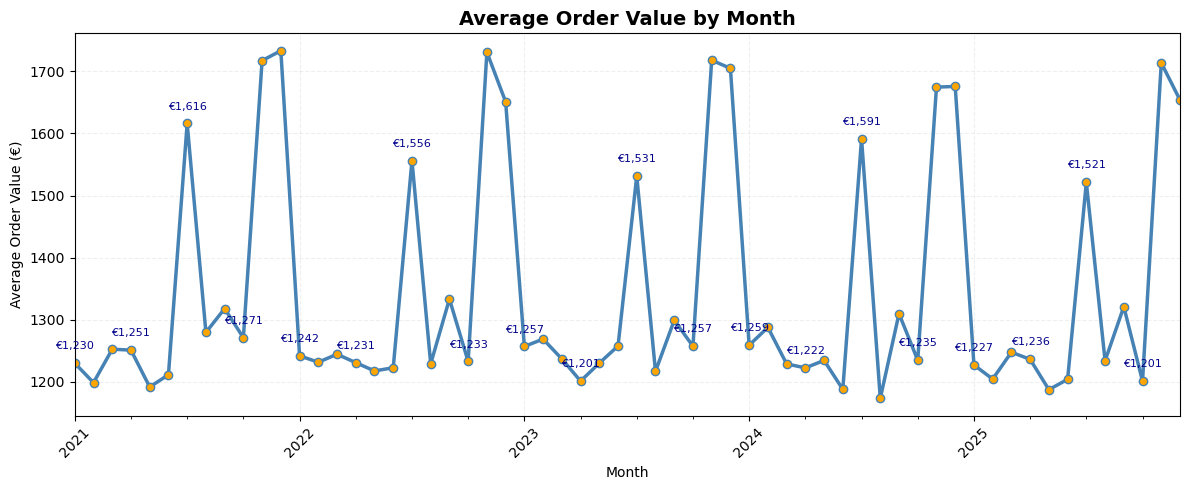

In [7]:
ax = avg_order_value.plot(
    kind="line",
    marker="o",
    color="steelblue",
    markerfacecolor="orange",
    linewidth=2.5,
    figsize=(12, 5),
    legend=False
)


for i, (date, value) in enumerate(avg_order_value.squeeze().items()):
    if i % 3 == 0:
        ax.annotate(
            f"€{value:,.0f}",
            xy=(date, value),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center",
            fontsize=8,
            color="darkblue"
        )

plt.title("Average Order Value by Month", fontsize=14, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Average Order Value (€)")
plt.xticks(rotation=45)
plt.grid(alpha=0.2, linestyle="--")
plt.tight_layout()
plt.show()

Average orders value trend is dimishing throughout the year according to the graph

There is a cyclical pattern trend for orders , with months by the end year seeing a surge of orders

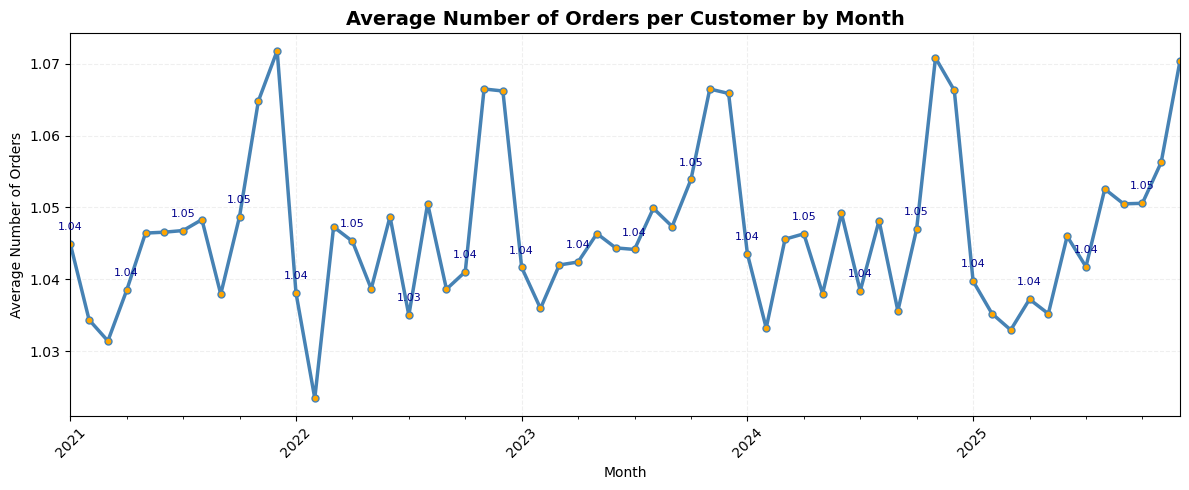

In [8]:
ax = avg_order_number.plot(
    kind="line",
    marker="o",
    color="steelblue",
    markerfacecolor="orange",
    linewidth=2.5,
    markersize=5,
    figsize=(12, 5),
    legend=False
)


for i, (date, value) in enumerate(avg_order_number.squeeze().items()):
    if i % 3 == 0:
        ax.annotate(
            f"{value:.2f}",
            xy=(date, value),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center",
            fontsize=8,
            color="darkblue"
        )

plt.title("Average Number of Orders per Customer by Month",
          fontsize=14, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Average Number of Orders")
plt.xticks(rotation=45)
plt.grid(alpha=0.2, linestyle="--")
plt.tight_layout()
plt.show()

<span style="color:red; font-size:14px; font-weight:bold;">
Lets estimate future customer value and purchasing potential
</span>

<span style="color:blue; font-size:20px; font-weight:bold;">
CLV Customer Lifetime Value
</span>

In [9]:
raws_trans = data[['customer_id','order_date','quantity','gross_sales']].copy()
raws_trans.head(3)

,customer_id,order_date,quantity,gross_sales
0,CUST-003102,2023-11-06,5,1350.19
1,CUST-003124,2025-12-24,8,3144.64
2,CUST-012496,2021-07-05,5,522.81


In [10]:
from pymc_marketing import clv

rfm_data =clv.utils.rfm_summary(
    raws_trans,
    customer_id_col    = 'customer_id',
    datetime_col       = 'order_date',
    monetary_value_col = 'gross_sales',
    datetime_format    = '%Y-%m-%d',
    time_unit          = 'W',
)

bgm =clv.BetaGeoModel()
bgm.build_model(data=rfm_data)
bgm

/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/pymc_marketing/clv/models/basic.py:116: UserWarning: T=0 is uninformative for model fitting. This occurs when a customer makes a purchase in the final observed time period.
  self._validate_rfm_data(data)


BG/NBD
            alpha ~ Weibull(2, 10)
      phi_dropout ~ Uniform(0, 1)
    kappa_dropout ~ Pareto(1, 1)
                r ~ Weibull(2, 1)
                a = Deterministic(f(kappa_dropout, phi_dropout))
                b = Deterministic(f(kappa_dropout, phi_dropout))
recency_frequency ~ BetaGeoNBD(a, b, r, alpha, <constant>)

In [11]:
rfrm_train_test_data = clv.utils.rfm_train_test_split(
    raws_trans,
    customer_id_col    = 'customer_id',
    datetime_col       = 'order_date',
    monetary_value_col = 'gross_sales',
    train_period_end   = '2024-12-31',
    datetime_format    = '%Y-%m-%d',
    time_unit          = 'W',
)
bgm_map = clv.BetaGeoModel()

bgm_map.fit(
    data   = rfrm_train_test_data,
    method = 'map',
)
bgm_map.fit_summary()

/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/pymc_marketing/clv/models/basic.py:116: UserWarning: T=0 is uninformative for model fitting. This occurs when a customer makes a purchase in the final observed time period.
  self._validate_rfm_data(data)


/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets"
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets"
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets"
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets"
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets"
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets"
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets"
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

alpha            2.786191e+02
phi_dropout      5.781734e-08
kappa_dropout    1.124385e+00
r                6.081686e+00
a                6.500897e-08
b                1.124385e+00
Name: value, dtype: float64

Lets plot the tracking incremental to test the accuracy of our customer purchase over time. On an horizon of 18 Months

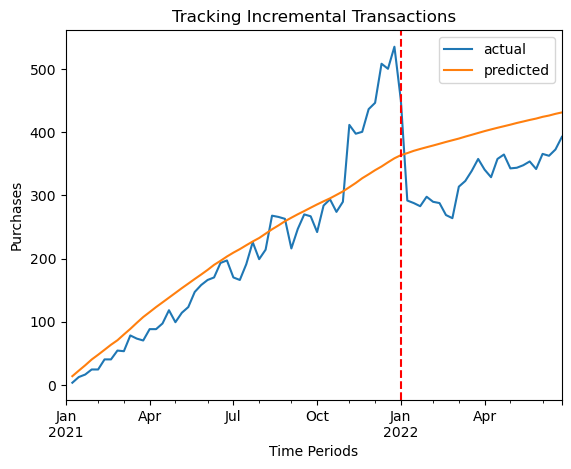

In [12]:
clv.plot_expected_purchases_over_time(
model              = bgm_map,
purchase_history   = raws_trans,
customer_id_col    = 'customer_id',
datetime_col       = 'order_date',
datetime_format    = '%Y-%m-%d',
time_unit          = 'W',
t                  = 78,
set_index_date     = True,
t_start_eval       = 52,
plot_cumulative    = False,
);

Before Jan 2022: Predictions broadly follow actual purchases, although they miss the year-end spike.¶
After Jan 2022: The model overpredicts purchases, indicating actual customer purchasing behavior declined relative to historical patterns.

/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/pytensor/link/numba/dispatch/basic.py:214: UserWarning: Numba will use object mode to run bg_nbd_rv{"(),(),(),(),()->(2)"}'s perform method. Set `pytensor.config.compiler_verbose = True` to see more details.
  warnings.warn(
Sampling: [alpha, kappa_dropout, phi_dropout, r, recency_frequency]


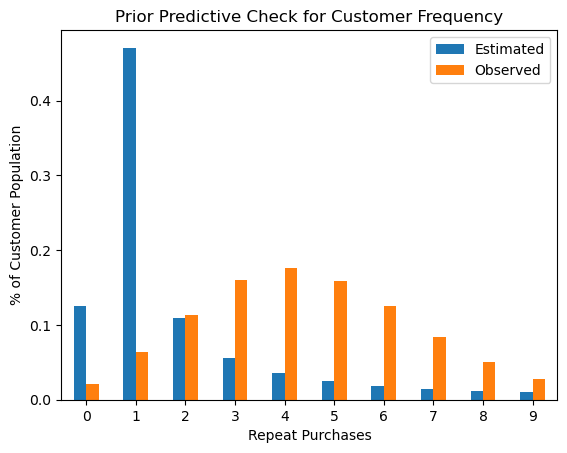

In [13]:
clv.plot_expected_purchases_ppc(bgm, ppc='prior');

It overestimates customers with 1 repeat purchase and substantially underestimates customers with 3–9 repeat purchases. This suggests the model is not adequately capturing the actual repeat-purchasing behavior.

In [14]:
bgm.fit()

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, phi_dropout, kappa_dropout, r]


/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets"
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 95 seconds.


/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets"
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

<xarray.DataTree>
Group: /
│   Attributes:
│       id:              06fdfbaf8d8047a7
│       model_type:      BG/NBD
│       version:         None
│       sampler_config:  {}
│       model_config:    {"alpha": {"dist": "Weibull", "kwargs": {"alpha": 2, "be...
├── Group: /posterior
│       Dimensions:        (chain: 4, draw: 1000)
│       Coordinates:
│         * chain          (chain) int64 32B 0 1 2 3
│         * draw           (draw) int64 8kB 0 1 2 3 4 5 6 ... 994 995 996 997 998 999
│       Data variables:
│           alpha          (chain, draw) float64 32kB 305.2 309.3 307.6 ... 313.7 310.8
│           phi_dropout    (chain, draw) float64 32kB 1.065e-06 2.244e-07 ... 4.626e-05
│           kappa_dropout  (chain, draw) float64 32kB 4.117 2.154 3.332 ... 1.78 4.753
│           r              (chain, draw) float64 32kB 6.67 6.751 6.71 ... 6.804 6.747
│           a              (chain, draw) float64 32kB 4.384e-06 4.833e-07 ... 0.0002199
│           b              (chain, draw) float64 32kB 4.117 2.154 3.332 ... 1.78 4.753
│       Attributes:
│           created_at:                 2026-10-22T08:16:14.079036+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.0.1
│           sample_dims:                ['chain', 'draw']
│           sampling_time:              95.1454610824585
│           tuning_steps:               1000
│           pymc_marketing_version:     1.0.0
├── Group: /sample_stats
│       Dimensions:                (chain: 4, draw: 1000)
│       Coordinates:
│         * chain                  (chain) int64 32B 0 1 2 3
│         * draw                   (draw) int64 8kB 0 1 2 3 4 5 ... 995 996 997 998 999
│       Data variables: (12/18)
│           tree_depth             (chain, draw) int64 32kB 1 4 3 4 4 3 ... 4 3 4 3 4 4
│           step_size              (chain, draw) float64 32kB 0.3792 0.3792 ... 0.3041
│           lp                     (chain, draw) float64 32kB -5.451e+05 ... -5.451e+05
│           largest_eigval         (chain, draw) float64 32kB nan nan nan ... nan nan
│           perf_counter_start     (chain, draw) float64 32kB 474.5 474.5 ... 499.5
│           index_in_trajectory    (chain, draw) int64 32kB 0 -5 -4 3 11 ... -10 -3 -3 4
│           ...                     ...
│           diverging              (chain, draw) bool 4kB False False ... False False
│           divergences            (chain, draw) int64 32kB 0 0 0 0 0 0 ... 0 0 0 0 0 0
│           energy                 (chain, draw) float64 32kB 5.451e+05 ... 5.451e+05
│           max_energy_error       (chain, draw) float64 32kB 1.335 -0.4885 ... -0.2278
│           step_size_bar          (chain, draw) float64 32kB 0.3407 0.3407 ... 0.2912
│           reached_max_treedepth  (chain, draw) bool 4kB False False ... False False
│       Attributes:
│           created_at:                 2026-10-22T08:16:14.086275+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.0.1
│           sample_dims:                ['chain', 'draw']
│           sampling_time:              95.1454610824585
│           tuning_steps:               1000
├── Group: /observed_data
│       Dimensions:            (customer_id: 24911, obs_var: 2)
│       Coordinates:
│         * customer_id        (customer_id) <U11 1MB 'CUST-000001' ... 'CUST-025000'
│         * obs_var            (obs_var) <U9 72B 'recency' 'frequency'
│       Data variables:
│           recency_frequency  (customer_id, obs_var) float64 399kB 254.0 8.0 ... 3.0
│       Attributes:
│           created_at:                 2026-10-22T08:16:14.088981+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creat

In [15]:
bgm.fit_summary()

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
alpha,310.2,4,300,320,1859,1845,1.00,0.092,0.064
phi_dropout,8.2e-05,8.2e-05,4.3e-06,0.00024,2074,1606,1.00,1.4e-06,1.8e-06
kappa_dropout,3.51e+01,1.37e+03,1.1,24,2868,2168,1.00,24,760
r,6.754,0.086,6.6,6.9,1844,2011,1.00,0.002,0.0014
a,0.004,0.2,8.5e-06,0.0021,1959,1724,1.00,0.0026,0.082
b,3.51e+01,1.37e+03,1.1,24,2867,2168,1.00,24,760


/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/pytensor/link/numba/dispatch/basic.py:214: UserWarning: Numba will use object mode to run bg_nbd_rv{"(),(),(),(),()->(2)"}'s perform method. Set `pytensor.config.compiler_verbose = True` to see more details.
  warnings.warn(
Sampling: [recency_frequency]


/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets"
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets"
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

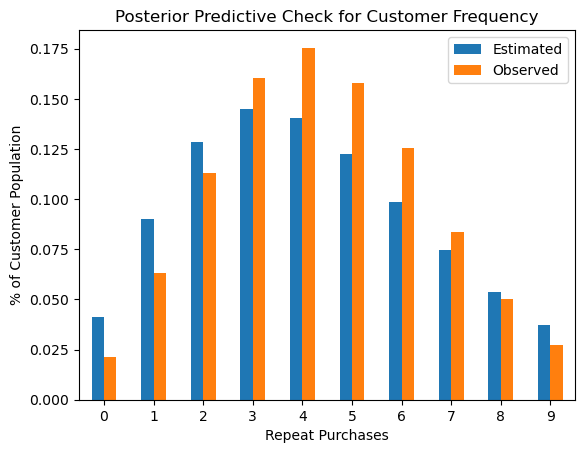

In [16]:
clv.plot_expected_purchases_ppc(bgm, ppc='posterior');

The posterieur overestimate the proportion of customers for first 3 purchase
and underestimate the proportion remaining purchase. the model estimate fewer purchases

In [17]:
pred = bgm.expected_purchases(
    data=rfrm_train_test_data,
    future_t=rfrm_train_test_data["test_T"]
)

predicted = pred.mean(("chain", "draw")).values
actual = rfrm_train_test_data["test_frequency"].values

In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(actual, predicted)
rmse = mean_squared_error(actual, predicted) ** 0.5

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 0.8258615095329068
RMSE: 1.0509698641083727


In [19]:
actual.mean(), predicted.mean()

(np.float64(1.0926862832395676), np.float64(1.1220234429984655))

customers with higher historical frequency and more recent activity have the highest expected future purchasing behavior

Lets Plot the probability of customer being alive

<Axes: title={'center': 'Probability Customer is Alive,\nby Frequency and Recency of a Customer'}, xlabel="Customer's Historical Frequency", ylabel="Customer's Recency">

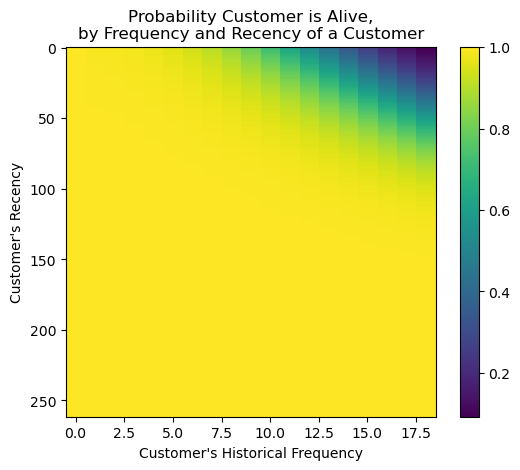

In [20]:
clv.plot_probability_alive_matrix(bgm)

Customers with many historical purchases but low recency have the highest risk of being inactive.¶
Recent purchasers generally have a high probability of remaining active.

<span style="color:red; font-size:14px; font-weight:bold;">
Estimate customer lifetime value using Gamma Gamma Model
</span>

In [21]:
data_df = rfm_data.copy()
returning_cst = data_df.query('frequency>0')
returning_cst[['frequency','monetary_value']].corr()

,frequency,monetary_value
frequency,1.000000,-0.010999
monetary_value,-0.010999,1.000000


In [22]:
model= clv.GammaGammaModel()
model.build_model(data=returning_cst)
model

Gamma-Gamma Model (Mean Transactions)
         p ~ Weibull(2, 1)
         q ~ Weibull(2, 1)
         v ~ Weibull(2, 10)
likelihood ~ Potential(f(q, p, v))

In [23]:
model.fit()
model.fit_summary()

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [p, q, v]


/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets"
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 30 seconds.


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
p,12.108,0.184,12,12,1647,1581,1.00,0.0045,0.0034
q,3.359,0.03,3.3,3.4,2119,1895,1.00,0.00065,0.00047
v,296.7,4.7,290,300,1616,1525,1.00,0.12,0.083


In [24]:
expected_spend = model.expected_customer_spend(data=returning_cst)
az.summary(expected_spend.isel(customer_id=range(10)), kind='stats')

,mean,sd,eti89_lb,eti89_ub
x[CUST-000001],1200,0.18,1200,1200
x[CUST-000002],1600,0.19,1600,1600
x[CUST-000003],1100,0.26,1100,1100
x[CUST-000004],2300,0.58,2300,2300
x[CUST-000005],1400,0.2,1400,1400
x[CUST-000006],1200,0.23,1200,1200
x[CUST-000007],2800,1.6,2800,2800
x[CUST-000008],1100,0.28,1100,1100
x[CUST-000009],760,0.76,760,760
x[CUST-000010],2800,1.5,2800,2800


In [25]:
az.summary(model.fit_result, var_names=["p", "q", "v"])

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
p,12.108,0.184,12,12,1647,1581,1.00,0.0045,0.0034
q,3.359,0.03,3.3,3.4,2119,1895,1.00,0.00065,0.00047
v,296.7,4.7,290,300,1616,1525,1.00,0.12,0.083


In [26]:
pred = expected_spend.mean(("chain", "draw")).values
actual = returning_cst["monetary_value"].values

from sklearn.metrics import mean_absolute_error
print("MAE:", mean_absolute_error(actual, pred))

MAE: 35.85707593525021


The Gamma-Gamma model looks statistically healthy:
r_hat = 1.00  showing excellent convergence.
ESS = 1,300–2,000  therefore a sufficient effective samples.
Low MCSE stable posterior estimates.
MAE = 35.82 predictions differ from observed average spend by about 36 monetary units per customer on average.
If typical customer spend is around 1,000–2,000, an MAE of 36 is only roughly 2–4%, which is quite small.

Text(0.5, 1.0, 'Expected Spend')

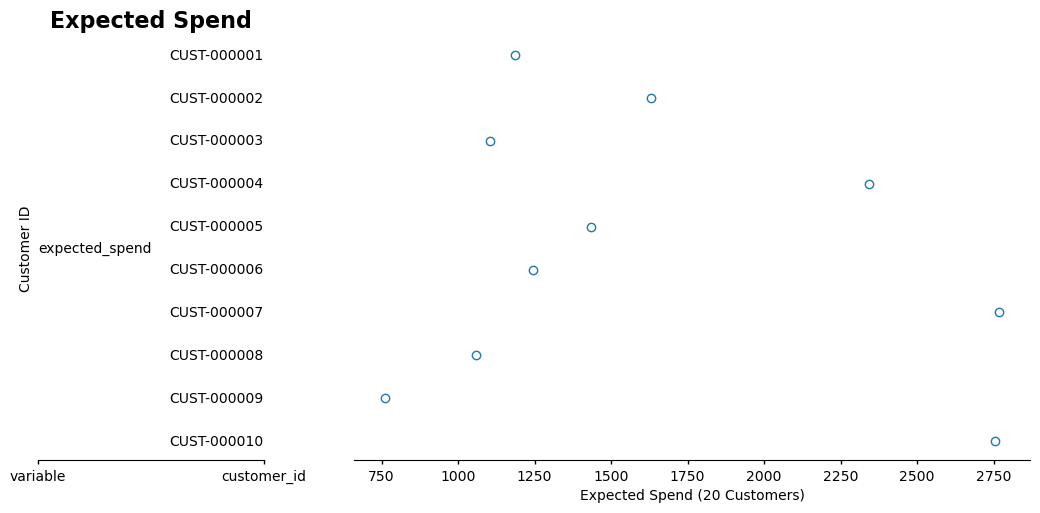

In [27]:
import arviz_plots as azp

pc = azp.plot_forest(
    expected_spend.isel(customer_id=range(10)).to_dataset(
        name="expected_spend"
    ),
    combined=True
)

label_ax, forest_ax = pc.viz["/"]["figure"].values.item().axes
forest_ax.set_xlabel("Expected Spend (20 Customers)")
label_ax.set_ylabel("Customer ID")
label_ax.set_title("Expected Spend", fontsize=16, fontweight="bold")

<span style="color:red; font-size:14px; font-weight:bold;">
lets group customer who share common characteristic and their behaviour over time in the next steps
</span>

<span style="color:blue; font-size:20px; font-weight:bold;">
Customer Cohorts
</span>

In [28]:
observation_date =pd.Timestamp('2025-12-31')
rfm_data_1 = rfm_data.copy()
rfm_data_1['acquisition_date']=(observation_date - pd.to_timedelta(rfm_data_1['T'],unit ='W'))
rfm_data_1['cohort'] = rfm_data_1['acquisition_date'].dt.to_period('M')

rfm_data_1["cohort"] = (
    rfm_data_1["acquisition_date"]
    .dt.to_period("Q")
)



max_time = int(rfm_data_1['T'].max())
survival = []

for t in range(max_time + 1):
    eligible = rfm_data_1[rfm_data_1['T'] >= t]

    rate = (
    eligible.assign(active=eligible['recency'] >= t)
    .groupby('cohort')['active']
    .mean()
    )
    survival.append(rate.rename(t))


survival_df = pd.DataFrame(survival)

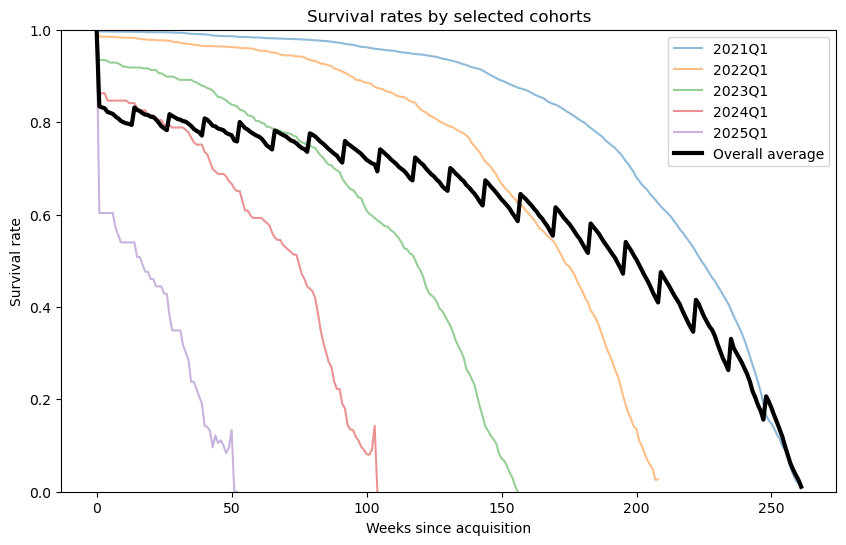

In [29]:
import matplotlib.pyplot as plt


overall = survival_df.mean(axis=1)

# Select a few cohorts
selected = ["2021Q1", "2022Q1", "2023Q1", "2024Q1", "2025Q1"]

ax = survival_df[selected].plot(figsize=(10, 6), alpha=0.5)


overall.plot(
    ax=ax,
    linewidth=3,
    color="black",
    label="Overall average"
)

ax.set(
    xlabel="Weeks since acquisition",
    ylabel="Survival rate",
    title="Survival rates by selected cohorts"
)
ax.set_ylim(0, 1)

plt.legend()
plt.show()

The survival curves show substantial variation across cohorts, with no single consistent retention pattern. More recent cohorts have shorter observation windows, making direct comparison across all cohorts difficult, even thought there is a path that can be seen as older customer survival rate is higher

A simple graphic to support the previous conclusion

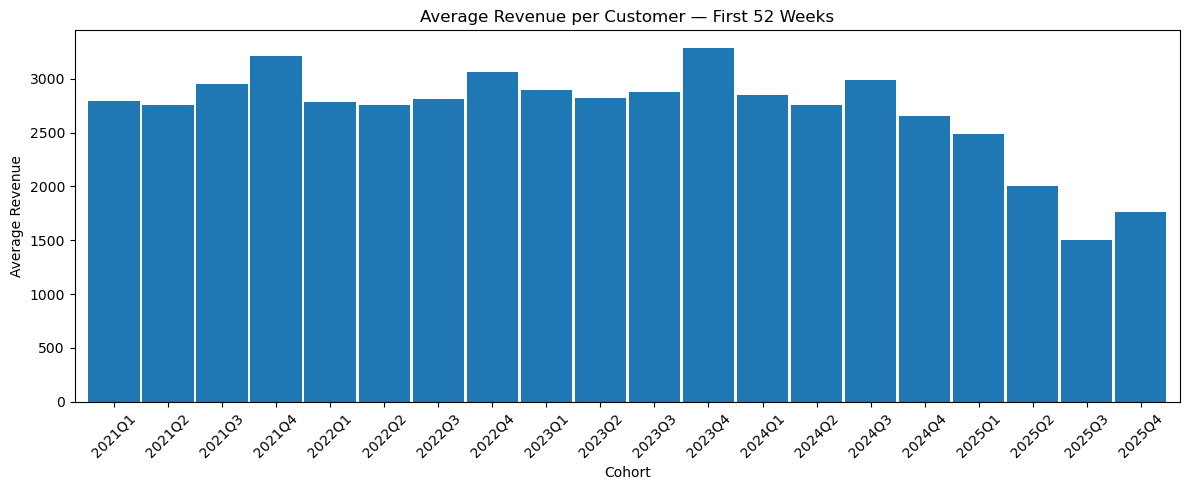

In [30]:
raw = raws_trans.copy()

raw["acquisition_date"] = (
    raw.groupby("customer_id")["order_date"].transform("min")
)


raw["cohort"] = raw["acquisition_date"].dt.to_period("Q")


raw["age_week"] = (
    (raw["order_date"] - raw["acquisition_date"]).dt.days // 7
)

revenue_52 = (
    raw[raw["age_week"] <= 52]
    .groupby(["cohort", "customer_id"])["gross_sales"].sum()
    .groupby("cohort").mean()
)



ax = revenue_52.plot(
    kind="bar",
    figsize=(12, 5),
    width=0.95  # closer bars
)

ax.set_title("Average Revenue per Customer — First 52 Weeks")
ax.set_xlabel("Cohort")
ax.set_ylabel("Average Revenue")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Higher survival rate for older cohots.

array([[<Axes: title={'center': 'recency'}>,
        <Axes: title={'center': 'frequency'}>],
       [<Axes: title={'center': 'monetary_value'}>, <Axes: >]],
      dtype=object)

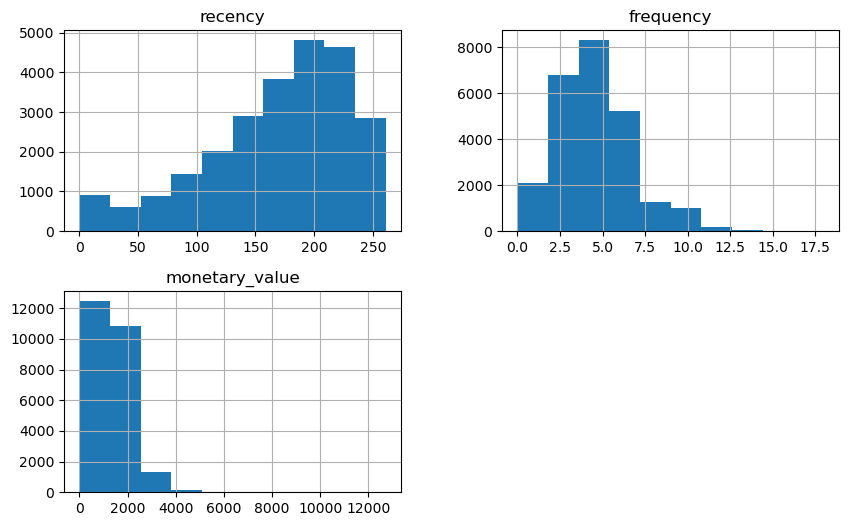

In [31]:
rfm_data[["recency", "frequency", "monetary_value"]].hist(figsize=(10, 6))

<span style="color:red; font-size:14px; font-weight:bold;">
lets group customer who share common characteristic and their behaviour with K-Means Cluster
</span>

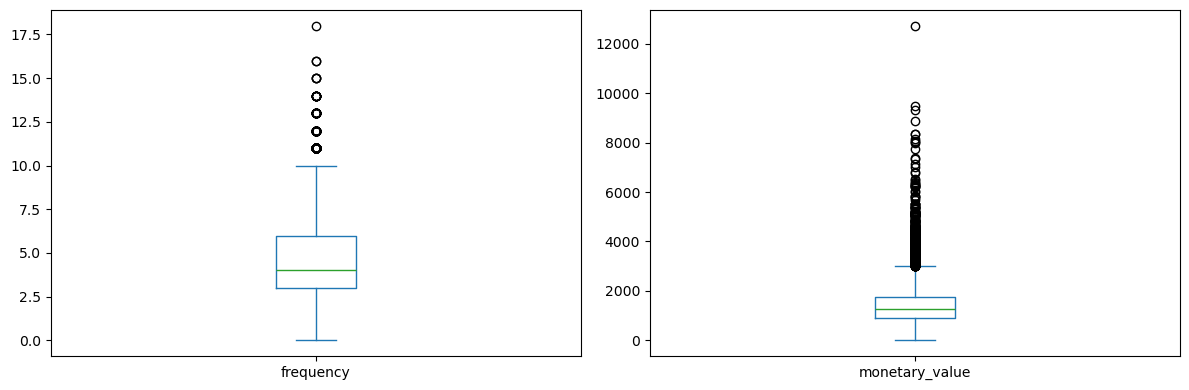

In [32]:
rfm_data[['frequency', 'monetary_value']].plot(
    kind="box",
    subplots=True,
    figsize=(12, 4)
)

plt.tight_layout()
plt.show()

In [33]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rfm_cluster = rfm_data.copy()

cols = ["recency", "frequency", "monetary_value"]

for col in cols:
    lower = rfm_cluster[col].quantile(0.01)
    upper = rfm_cluster[col].quantile(0.99)
    rfm_cluster[col] = rfm_cluster[col].clip(lower, upper)
    
rfm_cluster["recency"] = np.log1p(rfm_cluster["recency"])

X = rfm_cluster[cols]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init="auto")
    labels = km.fit_predict(X_scaled)

    print(
        f"k={k}, "
        f"silhouette={silhouette_score(X_scaled, labels):.3f}"
    )

k=2, silhouette=0.310
k=3, silhouette=0.308
k=4, silhouette=0.363
k=5, silhouette=0.305
k=6, silhouette=0.295
k=7, silhouette=0.308
k=8, silhouette=0.311


the biggest jump occurs between K=3 and K=4 by 0.058 indicating 4 clusters

In [34]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init="auto"
)

rfm_cluster["cluster"] = kmeans.fit_predict(X_scaled)

# Transfer cluster labels to original data
rfm_data["cluster"] = rfm_cluster["cluster"]

profile = rfm_data.groupby("cluster").agg(
    customers=("customer_id", "count"),
    avg_recency=("recency", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_monetary=("monetary_value", "mean")
).round(2)

profile

,customers,avg_recency,avg_frequency,avg_monetary
cluster,,,,
0,9196,203.11,6.79,1352.20
1,4989,158.71,3.48,2423.72
2,10067,152.86,3.15,951.22
3,659,1.37,0.21,181.02


cluster 1 have an higher average frequency, cluser 2 an higher average monetary compare with other

In [35]:
from pymc_marketing.clv import GammaGammaModel

gg_data = rfm_data[
    (rfm_data["monetary_value"] > 0) &
    (rfm_data["frequency"] > 0)
].copy()

gg = GammaGammaModel()
gg.fit(gg_data)

clv_12m = gg.expected_customer_lifetime_value(
    transaction_model=bgm,
    data=gg_data,
    future_t=12,          
    discount_rate=0.01,  
    time_unit="W"        
)


clv_18m = gg.expected_customer_lifetime_value(
    transaction_model=bgm,
    data=gg_data,
    future_t=18,
    discount_rate=0.01,
    time_unit="W"
)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [p, q, v]


/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets"
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 32 seconds.


In [36]:
gg_data["clv_12m"] = clv_12m.mean(("chain", "draw")).values
gg_data["clv_18m"] = clv_18m.mean(("chain", "draw")).values

expected_purch_12m = bgm.expected_purchases(
    data    = gg_data,
    future_t= 52
)
expected_purch_18m = bgm.expected_purchases(
    data    = gg_data,
    future_t = 78
)
gg_data['Expected Pirchase after 12 M']= expected_purch_12m.mean(("chain", "draw")).values
gg_data['Expected Pirchase after 18 M']= expected_purch_18m.mean(("chain", "draw")).values

In [37]:
demand_aft_12m = gg_data['Expected Pirchase after 12 M'].sum()
demand_aft_18m = gg_data['Expected Pirchase after 18 M'].sum()

print('Expected demand after a year', demand_aft_12m)
print('Expected demand after 18 months', demand_aft_18m)

Expected demand after a year 27435.314922822785
Expected demand after 18 months 41152.58801983988


the expected orders levels in a year is expected to reach 24735 orders and 41153 in 18 months 

In [38]:
monthly_orders = (
    data
    .groupby(data['order_date'].dt.to_period("M"))['order_id']
    .nunique()
)
print('Average monthly orders:', monthly_orders.mean())
print('Excepted Yearly orders:', monthly_orders.mean()*12)

Average monthly orders: 2301.9333333333334
Excepted Yearly orders: 27623.2


The average monthly orders is at 2302 orders 

In [39]:
test = data[
    (data["order_date"] >= "2025-01-01") &
    (data["order_date"] < "2026-01-01")
].copy()

actual_val_12m = (
    test.groupby("customer_id")["gross_sales"]
    .sum()
    .rename("actual_value_12m")
    .reset_index()
)

pred_val_gg = gg_data[
    ["customer_id", "clv_12m"]
].copy()


pred_val_gg["customer_id"] = pred_val_gg["customer_id"].astype(str)
actual_val_12m["customer_id"] = actual_val_12m["customer_id"].astype(str)

data_valid = pred_val_gg.merge(
    actual_val_12m,
    on="customer_id",
    how="left"
)

data_valid["actual_value_12m"] = (
    data_valid["actual_value_12m"].fillna(0)
)

In [40]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

actual = data_valid["actual_value_12m"]
predicted = data_valid["clv_12m"]

print("MAE:", mean_absolute_error(actual, predicted))
print("RMSE:", np.sqrt(mean_squared_error(actual, predicted)))

print("Predicted total:", predicted.sum())
print("Actual total:", actual.sum())

print(
    "Total error (%):",
    100 * (predicted.sum() / actual.sum() - 1)
)

MAE: 1318.7518044664876
RMSE: 1789.6746863845092
Predicted total: 36370012.44143455
Actual total: 37432342.92
Total error (%): -2.838001566815773


the BG/NBD + Gamma-Gamma model underpredicts aggregate revenue by only 2.84%. However, that does not necessarily mean it predicts each customer's CLV accurately. the predictions include a 1% monthly discount, whereas actual revenue is undiscounted. The −2.84% figure is therefore not a pure forecasting error

In [41]:
cluster_info = gg_data[
    ["customer_id", "cluster"]
].copy()

data_valid = data_valid.merge(
    cluster_info,
    on="customer_id",
    how="left"
)

segment_validation = data_valid.groupby("cluster").agg(
    customers=("customer_id", "count"),
    predicted=("clv_12m", "sum"),
    actual=("actual_value_12m", "sum")
)

segment_validation["error_pct"] = (
    (segment_validation["predicted"] /
     segment_validation["actual"] - 1) * 100
)

segment_validation.round(2)

,customers,predicted,actual,error_pct
cluster,,,,
0,9196,15377416.99,19405023.09,-20.76
1,4989,11395877.46,10212663.93,11.59
2,10067,9478172.00,7771546.73,21.96
3,131,118546.00,43109.17,174.99


the prediction of the actual value in the cluster sees some extreme variances accross the cluster, the cluster being
underpredicted , the other over predicted 

In [42]:
rfm_cluster = rfm_data.copy()

cols = ["recency", "frequency", "monetary_value"]


for col in cols:
    low = rfm_cluster[col].quantile(0.01)
    high = rfm_cluster[col].quantile(0.99)
    rfm_cluster[col] = rfm_cluster[col].clip(low, high)


rfm_cluster["recency"] = np.log1p(rfm_cluster["recency"])

X_scaled = StandardScaler().fit_transform(rfm_cluster[cols])

kmeans = KMeans(n_clusters=4, random_state=42, n_init="auto")
rfm_cluster["cluster"] = kmeans.fit_predict(X_scaled)

In [43]:
gg_data = gg_data.drop(columns="cluster", errors="ignore")
gg_data = gg_data.merge(
    rfm_cluster[["customer_id", "cluster"]],
    on="customer_id",
    how="left"
)

In [44]:
print(gg_data.columns)

Index(['customer_id', 'frequency', 'recency', 'T', 'monetary_value',
       'future_spend', 'clv_12m', 'clv_18m', 'Expected Pirchase after 12 M',
       'Expected Pirchase after 18 M', 'cluster'],
      dtype='object')


In [45]:
gg_data = gg_data.drop(
    columns=["cluster", "cluster_x", "cluster_y"],
    errors="ignore"
)
print(rfm_cluster.columns)

Index(['customer_id', 'frequency', 'recency', 'T', 'monetary_value',
       'cluster'],
      dtype='object')


In [46]:
gg_data = gg_data.merge(
    rfm_cluster[["customer_id", "cluster"]],
    on="customer_id",
    how="left"
)
gg_data[
    ["customer_id", "frequency", "recency",
     "monetary_value", "cluster"]
].head()

,customer_id,frequency,recency,monetary_value,cluster
0,CUST-000001,8.0,254.0,1178.073750,0
1,CUST-000002,9.0,204.0,1634.072222,0
2,CUST-000003,6.0,211.0,1091.946667,0
3,CUST-000004,6.0,79.0,2369.080000,1
4,CUST-000005,7.0,178.0,1430.670000,0


In [48]:
summary_text = pd.DataFrame({
    "Profile": [
        "Highest frequency (6.79), medium spend (€1,352)",
        "Lower frequency (3.48), highest spend (€2,424)",
        "Lower frequency (3.15), lower spend (€951)",
        "Very low frequency (1.07), low spend (€911), only 131 customers"
    ],

    "Suggested label": [
        "Frequent / Loyal",
        "High-Value",
        "Regular / Low-Value",
        "New / Limited-History"
    ],

    "CLV validation": [
        "Underpredicted −20.75%",
        "Overpredicted +11.58%",
        "Overpredicted +21.96%",
        "Overpredicted +174.98%"
    ]
}, index=[0, 1, 2, 3])

summary_text.index.name = "Cluster"

summary_text

,Profile,Suggested label,CLV validation
Cluster,,,
0,"Highest frequency (6.79), medium spend (€1,352)",Frequent / Loyal,Underpredicted −20.75%
1,"Lower frequency (3.48), highest spend (€2,424)",High-Value,Overpredicted +11.58%
2,"Lower frequency (3.15), lower spend (€951)",Regular / Low-Value,Overpredicted +21.96%
3,"Very low frequency (1.07), low spend (€911), o...",New / Limited-History,Overpredicted +174.98%


<span style="color:red; font-size:14px; font-weight:bold;">
lets find out the retention and revenue cohorts by acquisition date
</span>

In [49]:
acquisition = (data.groupby('customer_id')['order_date']
               .min()
               .rename('acquisition_date')
              )
data1 = data.merge(acquisition, on='customer_id')
from dateutil.relativedelta import relativedelta
data1['date_after_acq_year']= data1['acquisition_date'] + pd.DateOffset(years=1)
data_cohort = data1[['order_id','order_date','sales_channel','customer_id','customer_name','customer_age','gender',
                     'customer_segment','customer_country','region','acquisition_date','date_after_acq_year','gross_sales','marketing_channel']].copy()
Addition = gg_data[['customer_id', 'frequency', 'recency', 'T', 'monetary_value',
       'future_spend', 'clv_12m', 
       'Expected Pirchase after 12 M', 'cluster']].copy()
data_cohort = data_cohort.merge(Addition, on='customer_id')

In [50]:
data_acquisition = data_cohort[
    (data_cohort['order_date'] >= data_cohort['acquisition_date']) &
    (data_cohort['order_date'] < data_cohort['date_after_acq_year'])
].copy()

data_acquisition['acquisition_year'] = data_acquisition['acquisition_date'].dt.year

sales_year = data_acquisition.groupby('acquisition_year').agg(
    customers=('customer_id', 'nunique'),
    sales_year=('gross_sales', 'sum')
)
sales_year['average_sales'] = round(sales_year['sales_year']/sales_year['customers'] ,0)
sales_year

,customers,sales_year,average_sales
acquisition_year,,,
2021,16544,47792567.85,2889.0
2022,5518,15711736.46,2847.0
2023,1756,5327604.74,3034.0
2024,483,1495228.44,3096.0
2025,82,250792.43,3058.0


The new customer acquisition have been dropping considerably over the year , finding out the underlying cause behind
the drop will be important, are we observing a larger drop in specific countries, channels, gender or age group?

In [51]:
sales_year = data_acquisition.groupby(
    ['acquisition_year', 'gender', 'customer_country', 'region', 'marketing_channel']
).agg(
    customers=('customer_id', 'nunique'),
    sales_year=('gross_sales', 'sum')
).reset_index()
sales_year['average_sales'] = round(sales_year['sales_year'] / sales_year['customers'], 0)

In [52]:
sales_year.pivot_table(index='customer_country',
                       columns='acquisition_year',
                       values='customers',
                       aggfunc='sum')

acquisition_year,2021,2022,2023,2024,2025
customer_country,,,,,
Australia,1540,533,151,50,11
Canada,1618,505,200,49,11
Germany,2703,903,229,64,7
India,1317,424,143,58,6
UAE,940,328,121,33,6
UK,4609,1556,504,162,21
USA,18913,6224,2148,600,119


the acquistion by countries do not reveal much about the new acquisition by year, all countries have seen
a substantial drop by year 

In [53]:
sales_by_customers = data.groupby(
    data['order_date'].dt.year.rename('order_year')
).agg(
    customers=('customer_id', 'nunique'),
    sales_year=('gross_sales', 'sum')
).reset_index()
sales_by_customers 

,order_year,customers,sales_year
0,2021,16635,38328425.40
1,2022,16793,37944191.30
2,2023,16767,38116979.76
3,2024,16818,37987554.18
4,2025,16717,37585410.24


In [54]:
new_by_year = data_acquisition.groupby('acquisition_year').agg(
    new_customers=('customer_id', 'nunique'),
    new_sales=('gross_sales', 'sum')
).reset_index()

new_by_year['average_sales'] = round(new_by_year['new_sales'] / new_by_year['new_customers'], 0)
new_by_year = new_by_year.rename(columns={'acquisition_year': 'order_year'})

merged_year = sales_by_customers.merge(
    new_by_year[['order_year', 'new_customers', 'average_sales']],
    on='order_year',
    how='left'
)

In [55]:
merged_year

,order_year,customers,sales_year,new_customers,average_sales
0,2021,16635,38328425.40,16544,2889.0
1,2022,16793,37944191.30,5518,2847.0
2,2023,16767,38116979.76,1756,3034.0
3,2024,16818,37987554.18,483,3096.0
4,2025,16717,37585410.24,82,3058.0


By marketing channels, age group and countries show the same path of reduction, the drop is not attribute 
to a particular group it is spread over group and categories

<span style="color:blue; font-size:20px; font-weight:bold;">
Discount Analysis
</span>

In [56]:
data.groupby(
    data["order_date"].dt.year
)["customer_id"].nunique()

order_date
2021    16635
2022    16793
2023    16767
2024    16818
2025    16717
Name: customer_id, dtype: int64

In [57]:
data["order_year"] = data["order_date"].dt.year

data["acquisition_year"] = (
    data.groupby("customer_id")["order_year"].transform("min")
)

annual_customers = (
    data[["customer_id", "order_year", "acquisition_year"]]
    .drop_duplicates(["customer_id", "order_year"])
    .assign(
        customer_type=lambda x: x["order_year"].eq(
            x["acquisition_year"]
        ).map({True: "New", False: "Returning"})
    )
    .groupby(["order_year", "customer_type"])
    .size()
    .unstack(fill_value=0)
)

annual_customers

customer_type,New,Returning
order_year,,
2021,16635,0
2022,5631,11162
2023,1858,14909
2024,583,16235
2025,204,16513


In [58]:
data_aov = data[['order_id','order_date','order_year','sales_channel','customer_id','discount_amount','gross_sales','customer_segment',
                   'customer_type','customer_country']].copy()
data_aov['discount_applied']= np.where(data_aov['discount_amount'] >0, "Applied", "Not Applied")
data_4 = data_aov.groupby(
    ["order_year", "discount_applied"]).agg(
    total_sales   =("gross_sales", "sum"),
    orders_volumes=('order_id', 'nunique')
).reset_index()
data_4['AOV'] = round(data_4['total_sales']/data_4['orders_volumes']).round(2)
data_aov = data_4.copy()
data_aov

,order_year,discount_applied,total_sales,orders_volumes,AOV
0,2021,Applied,34071380.66,24117,1413.0
1,2021,Not Applied,4257044.74,3437,1239.0
2,2022,Applied,33653702.94,24045,1400.0
3,2022,Not Applied,4290488.36,3519,1219.0
4,2023,Applied,33716389.68,24038,1403.0
5,2023,Not Applied,4400590.08,3594,1224.0
6,2024,Applied,33515166.99,24052,1393.0
7,2024,Not Applied,4472387.19,3716,1204.0
8,2025,Applied,33235781.27,24000,1385.0
9,2025,Not Applied,4349628.97,3598,1209.0


In [59]:
new_data = data.groupby('order_year').agg(
    customers=('customer_id', 'nunique'),
    total_sales=('gross_sales', 'sum'),
    total_discount=('discount_amount', 'sum')
).reset_index()

new_data['average_sales'] = (
    new_data['total_sales'] / new_data['customers']
).round(0)

new_data['ratio_discount'] = (
    new_data['total_discount'] / new_data['total_sales'] * 100
).round(2)

new_data_1 = new_data.merge(annual_customers[["New","Returning"]],
                            on='order_year',
                            how='left')

new_data_1 


,order_year,customers,total_sales,total_discount,average_sales,ratio_discount,New,Returning
0,2021,16635,38328425.40,6637452.44,2304.0,17.32,16635,0
1,2022,16793,37944191.30,6613153.09,2260.0,17.43,5631,11162
2,2023,16767,38116979.76,6584731.05,2273.0,17.28,1858,14909
3,2024,16818,37987554.18,6525341.36,2259.0,17.18,583,16235
4,2025,16717,37585410.24,6458668.88,2248.0,17.18,204,16513


In [60]:
new_data_3 = data[['order_id','order_date','order_year','sales_channel','customer_id','discount_amount','gross_sales','customer_segment',
                   'customer_type','customer_country']].copy()
new_data_3['discount_applied']= np.where(new_data_3['discount_amount'] >0, "Applied", "Not Applied")
new_data_4 = new_data_3.groupby(
    ["order_year", "discount_applied"]).agg(
    total_sales   =("gross_sales", "sum"),
    orders_volumes=('order_id', 'nunique')
).reset_index()
new_data_4['AOV'] = round(new_data_4['total_sales']/new_data_4['orders_volumes']).round(2)



In [61]:
new_data_4 = new_data_3.groupby(
    ["order_year", "discount_applied"]).agg(
    total_sales   =("gross_sales", "sum"),
    orders_volumes=('order_id', 'nunique'),
    total_discount=('discount_amount','sum')
).reset_index()
new_data_4['netAOV'] = round((new_data_4['total_sales']-new_data_4['total_discount'])/new_data_4['orders_volumes']).round(2)
new_data_4

,order_year,discount_applied,total_sales,orders_volumes,total_discount,netAOV
0,2021,Applied,34071380.66,24117,6637452.44,1138.0
1,2021,Not Applied,4257044.74,3437,0.00,1239.0
2,2022,Applied,33653702.94,24045,6613153.09,1125.0
3,2022,Not Applied,4290488.36,3519,0.00,1219.0
4,2023,Applied,33716389.68,24038,6584731.05,1129.0
5,2023,Not Applied,4400590.08,3594,0.00,1224.0
6,2024,Applied,33515166.99,24052,6525341.36,1122.0
7,2024,Not Applied,4472387.19,3716,0.00,1204.0
8,2025,Applied,33235781.27,24000,6458668.88,1116.0
9,2025,Not Applied,4349628.97,3598,0.00,1209.0


In [62]:
new_data_4.pivot(
    index="order_year",
    columns="discount_applied",
    values="netAOV"
)

discount_applied,Applied,Not Applied
order_year,,
2021,1138.0,1239.0
2022,1125.0,1219.0
2023,1129.0,1224.0
2024,1122.0,1204.0
2025,1116.0,1209.0


In [63]:
new_data_5 = data[['customer_id','discount_amount','gross_sales','customer_segment',
                   'customer_type','profit']].copy()
new_year_6 = new_data_5.groupby('customer_id').agg(
                   customer_type=('customer_type', 'first'),
                   customer_segment=('customer_segment', 'first'),
                   total_sales   =("gross_sales", "sum"),
                   total_profits =('profit', 'sum'),
                   total_discount=('discount_amount','sum'))

new_year_6['discount_rate'] = (new_year_6['total_discount']/new_year_6['total_sales']*100)
new_year_6['profit_rate'] = (new_year_6['total_profits']/new_year_6['total_sales']*100) 

new_data_7 = gg_data[['customer_id', 'frequency', 'recency', 'T', 'monetary_value',
       'future_spend', 'clv_12m', 'Expected Pirchase after 12 M', 'cluster']].copy()

data_discount = new_data_7.merge(
    new_year_6, on='customer_id', how='left'
)

the discount applied have sensibly similar effects on the net average orders values reducing by approximateively 9.2%

comparing the effect of discount on some keys indicators

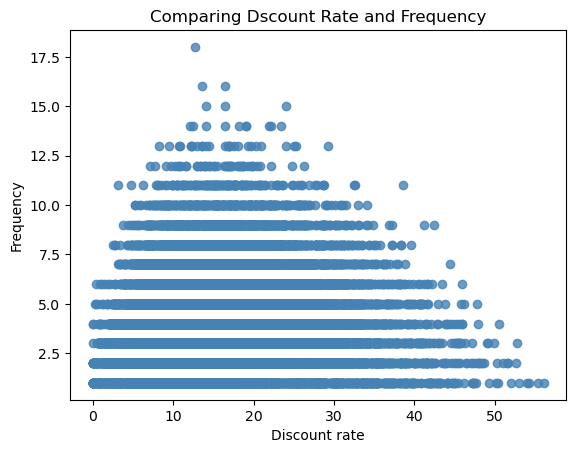

In [64]:
x = data_discount['discount_rate']
y = data_discount['frequency']

plt.scatter(x,y, color='steelblue', alpha=0.8)
plt.xlabel('Discount rate')
plt.ylabel('Frequency')
plt.title('Comparing Dscount Rate and Frequency')
plt.show()

In [65]:
data_discount[['discount_rate', 'frequency']].corr(method='spearman')

,discount_rate,frequency
discount_rate,1.000000,0.061845
frequency,0.061845,1.000000


Higher discount exposure is not meaningfully associated with more repeat purchases.

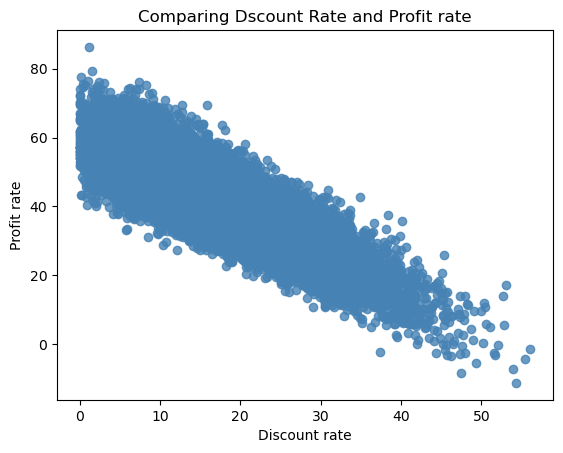

In [66]:
x = data_discount['discount_rate']
y = data_discount['profit_rate']

plt.scatter(x,y, color='steelblue', alpha=0.8)
plt.xlabel('Discount rate')
plt.ylabel('Profit rate')
plt.title('Comparing Dscount Rate and Profit rate')
plt.show()

In [67]:
data_discount[['discount_rate', 'profit_rate']].corr(method='spearman')

,discount_rate,profit_rate
discount_rate,1.000000,-0.786432
profit_rate,-0.786432,1.000000


discount rate strongly negatively associated with profit rate

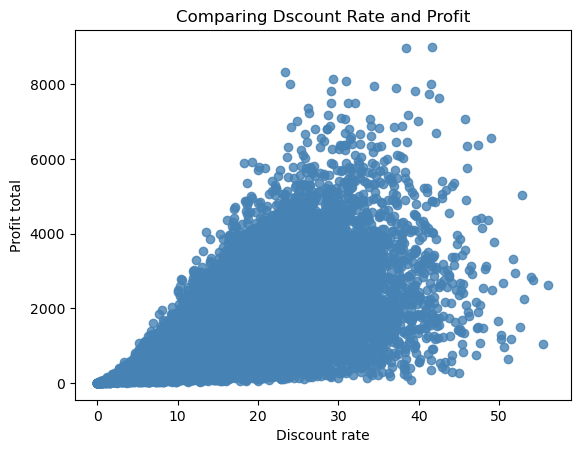

In [68]:
x = data_discount['discount_rate']
y = data_discount['total_discount']

plt.scatter(x,y, color='steelblue', alpha=0.8)
plt.xlabel('Discount rate')
plt.ylabel('Profit total')
plt.title('Comparing Dscount Rate and Profit')
plt.show()

In [69]:
data_discount[['discount_rate', 'total_profits']].corr(method='spearman')

,discount_rate,total_profits
discount_rate,1.000000,-0.159769
total_profits,-0.159769,1.000000


Repeat purchases: +0.062 — negligible relationship with discount rate.
Profit margin: −0.78 — strong negative relationship with discount rate.
Total profit: −0.16 — weak negative relationship. Conclusion: Higher discounts are associated with substantially lower profit margins, without a meaningful increase in repeat purchases.

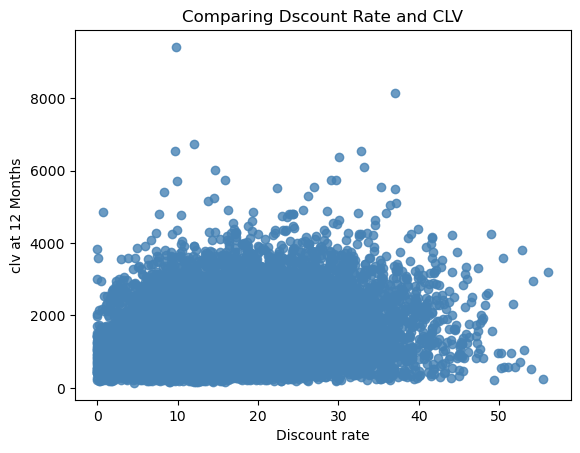

In [70]:
x = data_discount['discount_rate']
y = data_discount['clv_12m']

plt.scatter(x,y, color='steelblue', alpha=0.8)
plt.xlabel('Discount rate')
plt.ylabel('clv at 12 Months')
plt.title('Comparing Dscount Rate and CLV')
plt.show()

In [71]:
data_discount[['discount_rate', 'clv_12m']].corr(method='spearman')

,discount_rate,clv_12m
discount_rate,1.000000,0.222134
clv_12m,0.222134,1.000000


we cannot conclude that discoun rate is related with a longer CLV at 12 months from the graph however 
the spearman coefficient shows some small positive correlation

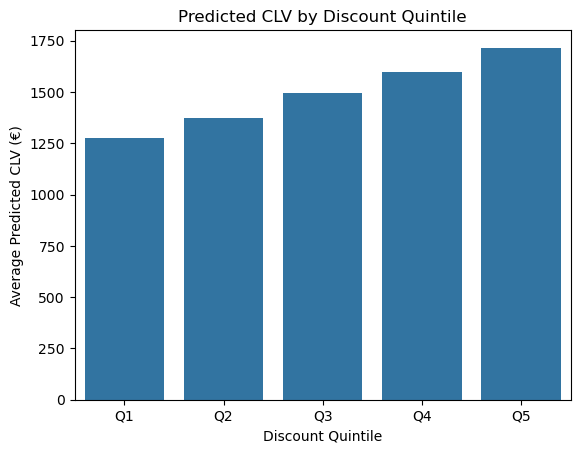

In [72]:
data_discount['discount_group'] = pd.qcut(
    data_discount['discount_rate'],
    q=5,
    labels=['Q1', 'Q2', 'Q3', 'Q4', 'Q5']
)

sns.barplot(
    data=data_discount,
    x='discount_group',
    y='clv_12m',
    estimator='mean',
    errorbar=None
)

plt.xlabel('Discount Quintile')
plt.ylabel('Average Predicted CLV (€)')
plt.title('Predicted CLV by Discount Quintile')
plt.show()

Discounts and profitability: Higher discount rates are strongly associated with lower profit margins (−0.78). Discounts and repeat purchases: Almost no association (+0.062). Discounts and CLV: A modest positive association (+0.222), but this does not prove discounts generate higher future value. from the conclusions that discount rate and profit rate and profit are negatively correlated and now that higher discount is only a trade off to compensate the loss profit with a lifetime value however we cannot conclude that, so we cannot conclude that the discount are meaningless, we also do not know why the sales are decreasing over the few year

<span style="color:blue; font-size:20px; font-weight:bold;">
Returns Analysis
</span>

In [73]:
data_p = data[['order_id','order_date','customer_id', 'return_status','return_reason','customer_rating',
'review_sentiment','customer_review','quantity','gross_sales','discount_amount','profit','order_year']].copy()
data_s = data_cohort[['customer_id','marketing_channel','customer_age','gender','sales_channel']].copy()
data_s = data_s.drop_duplicates(subset='customer_id')
data_t = Addition[['customer_id','cluster']].copy()

data_returns = (data_p.merge(data_s,on ='customer_id',how='left')
                      .merge(data_t,on ='customer_id',how='left'))

returns_by_years = (
    data_returns.groupby(['order_year', 'return_status'])
    .agg(
        total_sales=('gross_sales', 'sum'),
        orders_volumes=('order_id', 'nunique')
    )
    .reset_index()
)

returns_by_years['annual_orders'] = (
    returns_by_years.groupby('order_year')['orders_volumes']
    .transform('sum')
)

returns_by_years['return_rate'] = (
    returns_by_years['orders_volumes'] /
    returns_by_years['annual_orders'] * 100
).round(2)

returns_summary = returns_by_years.pivot(
    index='order_year',
    columns='return_status',
    values='orders_volumes'
).reset_index()

returns_summary['total_orders'] = (
    returns_summary['Kept'] + returns_summary['Returned']
)

returns_summary['return_rate'] = (
    returns_summary['Returned'] /
    returns_summary['total_orders'] * 100
).round(2)

returns_summary

return_status,order_year,Kept,Returned,total_orders,return_rate
0,2021,25729,1825,27554,6.62
1,2022,25739,1825,27564,6.62
2,2023,25744,1888,27632,6.83
3,2024,25816,1952,27768,7.03
4,2025,25626,1972,27598,7.15


In [74]:
returns_summary = returns_by_years.pivot(
    index='order_year',
    columns='return_status',
    values='total_sales'
).reset_index()

returns_summary['total_sales'] = (
    returns_summary['Kept'] + returns_summary['Returned']
)

returns_summary['loss_rate'] = (
    returns_summary['Returned'] /
    returns_summary['total_sales'] * 100
).round(2)
returns_summary

return_status,order_year,Kept,Returned,total_sales,loss_rate
0,2021,35994400.72,2334024.68,38328425.40,6.09
1,2022,35705433.10,2238758.20,37944191.30,5.90
2,2023,35837874.78,2279104.98,38116979.76,5.98
3,2024,35601545.38,2386008.80,37987554.18,6.28
4,2025,35131104.82,2454305.42,37585410.24,6.53


The results show that returns contribute to revenue losses, but are unlikely to fully explain the sales decline.
2021: €2.33 million returned (6.09%).
2025: €2.45 million returned (6.53%)
Increase: Approximately €120,281, or 0.44 percentage points. Meanwhile, annual gross sales declined by approximately €743,015 between 2021 and 2025. Conclusion: Returns represent a meaningful revenue exposure, but their increase is relatively modest compared with the decline in gross sales.

In [75]:
returns_reasons_summary = (
    data_returns[data_returns['return_status'] == 'Returned']
    .groupby('return_reason')
    .agg(
        returned_sales=('gross_sales', 'sum'),
        returned_orders=('order_id', 'nunique')
    )
    .sort_values('returned_sales', ascending=False)
)
returns_reasons_summary

,returned_sales,returned_orders
return_reason,,
Wrong Product,1515608.22,1237
Changed Mind,1485740.39,1204
Size Issue,1477236.80,1182
Damaged Product,1477231.47,1138
Late Delivery,1464794.68,1172
Defective Product,1446741.93,1174
Other,1413537.94,1208
Product Not as Expected,1411310.65,1147


In [76]:
returns_channel = (
    data_returns[data_returns['return_status'] == 'Returned']
    .groupby('sales_channel')
    .agg(
        returned_sales=('gross_sales', 'sum'),
        returned_orders=('order_id', 'nunique')
    )
    .sort_values('returned_sales', ascending=False)
)
returns_channel

,returned_sales,returned_orders
sales_channel,,
Mobile App,4790199.45,3913
Website,3974832.32,3242
Marketplace,1702122.41,1365
Social Media,1180721.73,901


the largest returns volumes are observed in mobile orders and website, quiet understandable since mobile app and 
website probably display similar object and vsited by the same person, social media see less

In [77]:
returns_channel = data_returns[
    data_returns['return_status'] == 'Returned'
].copy()

returns_channel_summary = returns_channel.groupby(
    ['order_year', 'sales_channel']
).agg(
    returned_sales=('gross_sales', 'sum'),
    returned_orders=('order_id', 'nunique')
).reset_index()

returns_channel_summary_p = returns_channel_summary.pivot(
    index='order_year',
    columns='sales_channel',
    values='returned_sales'
).reset_index()

returns_channel_summary_p

sales_channel,order_year,Marketplace,Mobile App,Social Media,Website
0,2021,318560.58,918369.16,240743.70,852553.00
1,2022,352902.48,904759.30,224766.65,743945.48
2,2023,344657.72,901739.65,209336.05,818034.19
3,2024,372199.64,982002.82,234940.71,782139.27
4,2025,313801.99,1083328.52,270934.62,778160.38


In [78]:
channel_total = data_returns.groupby(
    ['order_year', 'sales_channel']
).agg(
    total_sales=('gross_sales', 'sum'),
    total_orders=('order_id', 'nunique')
).reset_index()

channel_comparison = channel_total.merge(
    returns_channel_summary,
    on=['order_year', 'sales_channel'],
    how='left'
)

channel_comparison['return_rate'] = (
    channel_comparison['returned_orders'] /
    channel_comparison['total_orders'] * 100
).round(2)

channel_comparison['returned_sales_rate'] = (
    channel_comparison['returned_sales'] /
    channel_comparison['total_sales'] * 100
).round(2)

channel_comparison.pivot(
    index='order_year',
    columns='sales_channel',
    values='return_rate'
).round(2)

sales_channel,Marketplace,Mobile App,Social Media,Website
order_year,,,,
2021,6.37,6.60,6.32,6.85
2022,6.41,6.73,7.06,6.44
2023,6.41,6.94,6.69,6.94
2024,7.20,7.12,6.48,6.96
2025,6.47,7.60,7.54,6.81


the return rate from social media compared with the total saw the largest increase of return rate
most are stable over the years.

<span style="color:blue; font-size:20px; font-weight:bold;">
Customer Experience
</span>

In [79]:
ratings = data_returns.groupby(
    ['order_year']
).agg(
    ratings =('customer_rating', 'mean')
).reset_index()
ratings

,order_year,ratings
0,2021,3.673111
1,2022,3.677258
2,2023,3.683122
3,2024,3.675765
4,2025,3.675830


Average ratings for product do not significantly changed over the year

In [80]:
reviews = data_returns.groupby(
    ['order_year', 'review_sentiment']
).agg(
    reviews=('review_sentiment', 'count')
).reset_index()

reviews.pivot(
    index='order_year',
    columns='review_sentiment',
    values='reviews'
).round(2)

review_sentiment,Negative,Neutral,Positive
order_year,,,
2021,150,7094,15591
2022,154,6950,15555
2023,156,6800,15766
2024,163,6926,15581
2025,169,6914,15590


Neither average ratings nor review sentiment indicates a substantial deterioration in customer experience that could explain declining sales.

In [81]:
reviews_by_status = (
    data_returns.groupby(['return_status', 'review_sentiment'])
    .size()
    .unstack(fill_value=0)
)
reviews_by_status

review_sentiment,Negative,Neutral,Positive
return_status,,,
Kept,792,34684,78083


<span style="color:red; font-size:14px; font-weight:bold;">
lets find out the customers at risk
</span>

<span style="color:blue; font-size:20px; font-weight:bold;">
Churn Analysis
</span>

In [82]:
purchase_gaps = data.sort_values(
    ['customer_id', 'order_date']
).copy()

purchase_gaps['gap_days'] = (
    purchase_gaps.groupby('customer_id')['order_date']
    .diff()
    .dt.days
)

gaps = purchase_gaps['gap_days'].dropna()


print(gaps.describe(percentiles=[.25, .50, .75, .90, .95]))

count    113205.000000
mean        259.664441
std         244.460931
min           0.000000
25%          77.000000
50%         187.000000
75%         366.000000
90%         598.000000
95%         754.000000
max        1796.000000
Name: gap_days, dtype: float64


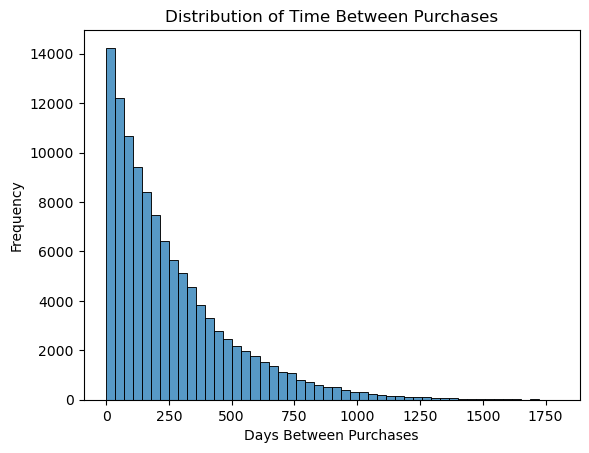

In [83]:
sns.histplot(gaps, bins=50)

plt.xlabel('Days Between Purchases')
plt.ylabel('Frequency')
plt.title('Distribution of Time Between Purchases')
plt.show()

In [84]:
last_date = (data.groupby('customer_id')['order_date']
               .max()
               .rename('last_purchase_date')
               .reset_index()
              )
last_date['diff_days'] = ( pd.Timestamp('2025-12-31') - last_date['last_purchase_date']).dt.days
data_churn = last_date.merge(
    data_discount,
    on='customer_id',
    how='left',
    validate='one_to_one'
)

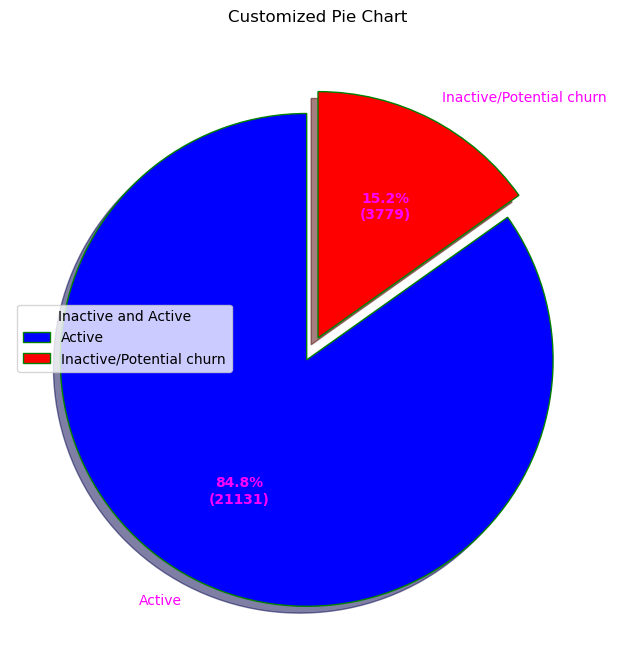

In [85]:
data_churn['churn/inactive']= data_churn['diff_days'].apply(lambda x:'Inactive/Potential churn' if x > 598 else 'Active')

churn_col = data_churn['churn/inactive']
churn_col_value = churn_col.value_counts()
explode =(0.1,0.0)
colors =('blue','red')
wp = {'linewidth':1, 'edgecolor':'green'}
my_labels    = ['Active','Inactive/Potential churn']

def func(pct, allvalues):
    absolute = int(pct / 100.*np.sum(allvalues))
    return "{:.1f}%\n({:d})".format(pct,absolute)

fig, ax = plt.subplots(figsize=(12,8))
wedges, texts, autotexts = ax.pie(churn_col_value,
                                  autopct= lambda pct: func(pct,churn_col_value),
                                  explode= explode,
                                  labels = my_labels,
                                  shadow =True,
                                  colors =colors,
                                  startangle=90,
                                  wedgeprops=wp,
                                  textprops=dict(color='magenta'))
ax.legend(wedges,my_labels,
          title ='Inactive and Active',
          loc   ='center left')
plt.setp(autotexts, size=10, weight='bold')
ax.set_title('Customized Pie Chart')
plt.show()

 The useful new finding is that 15.2% of historically observed customers exceeded the 598-day inactivity threshold by the end of 2025

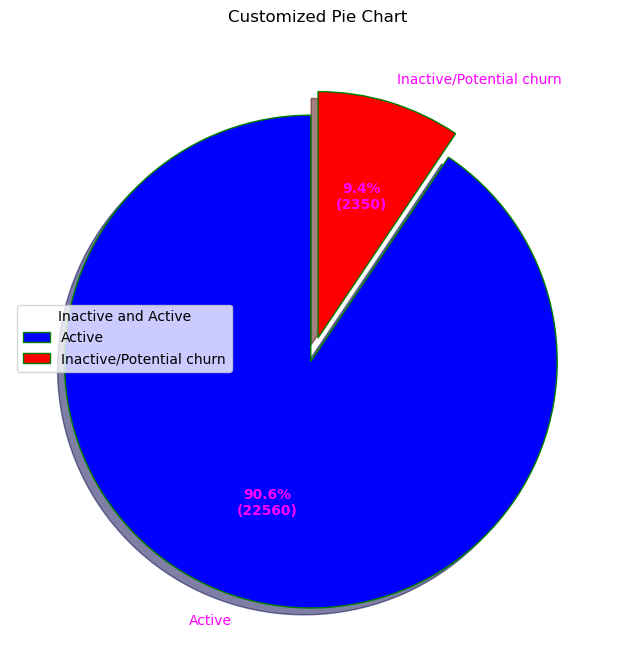

In [86]:
data_churn['churn/inactive']= data_churn['diff_days'].apply(lambda x:'Inactive/Potential churn' if x > 754 else 'Active')

churn_col = data_churn['churn/inactive']
churn_col_value = churn_col.value_counts()
explode =(0.1,0.0)
colors =('blue','red')
wp = {'linewidth':1, 'edgecolor':'green'}
my_labels    = ['Active','Inactive/Potential churn']

def func(pct, allvalues):
    absolute = int(pct / 100.*np.sum(allvalues))
    return "{:.1f}%\n({:d})".format(pct,absolute)

fig, ax = plt.subplots(figsize=(12,8))
wedges, texts, autotexts = ax.pie(churn_col_value,
                                  autopct= lambda pct: func(pct,churn_col_value),
                                  explode= explode,
                                  labels = my_labels,
                                  shadow =True,
                                  colors =colors,
                                  startangle=90,
                                  wedgeprops=wp,
                                  textprops=dict(color='magenta'))
ax.legend(wedges,my_labels,
          title ='Inactive and Active',
          loc   ='center left')
plt.setp(autotexts, size=10, weight='bold')
ax.set_title('Customized Pie Chart')
plt.show()

754 days as the provisional prolonged-inactivity threshold, given the observed purchase intervals and unknown product types.There is a distinction between annual purchasing activity, prolonged inactivity, and actual churn. They should not be treated as interchangeable.

the probaility of churn ratio using a Beyesian Approach

In [87]:
from pymc_marketing.clv import BetaGeoModel

rfm_2025 = clv.utils.rfm_summary(
    data,
    customer_id_col="customer_id",
    datetime_col="order_date",
    monetary_value_col="gross_sales",
    observation_period_end="2025-12-31",
    time_unit="W"
)

bgm_2025 = BetaGeoModel()
bgm_2025.fit(rfm_2025)

rfm_2025["p_alive"] = (
    bgm_2025.expected_probability_alive(
        data=rfm_2025
    ).mean(dim=("chain", "draw")).values
)

rfm_2025["churn_risk"] = 1 - rfm_2025["p_alive"]

/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/pymc_marketing/clv/models/basic.py:116: UserWarning: T=0 is uninformative for model fitting. This occurs when a customer makes a purchase in the final observed time period.
  self._validate_rfm_data(data)
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, phi_dropout, kappa_dropout, r]


/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets"
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 84 seconds.


/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets"
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

In [88]:
rfm_2025.head(5)

,customer_id,frequency,recency,T,monetary_value,p_alive,churn_risk
0,CUST-000001,8.0,254.0,255.0,1178.073750,0.999972,0.000028
1,CUST-000002,9.0,204.0,244.0,1634.072222,0.999917,0.000083
2,CUST-000003,6.0,211.0,241.0,1091.946667,0.999933,0.000067
3,CUST-000004,6.0,79.0,87.0,2369.080000,0.999958,0.000042
4,CUST-000005,7.0,178.0,237.0,1430.670000,0.999857,0.000143


In [89]:
az.summary(
    bgm_2025.idata,
    var_names=['a', 'b']
)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
a,0.0012,0.011,1e-05,0.0022,1669,1468,1.00,0.00032,0.0046
b,11,7.68e+01,1.1,24,2856,1909,1.00,1.8,29


Purchase frequency is relatively low, with long intervals between purchases. Prolonged inactivity does not necessarily indicate churn, particularly when product categories are unknown. BG/NBD estimates negligible permanent dropout (even for the cut off date on end december 2024), but this remains a model assumption rather than proof of customer retention. The dataset does not provide sufficient evidence to establish a reliable business churn rate.Approximately 9.4% of customers show prolonged inactivity and may warrant re-engagement. Their actual probability of churning remains uncertain.

<span style="color:blue; font-size:20px; font-weight:bold;">
Bayesian Modelling
</span>

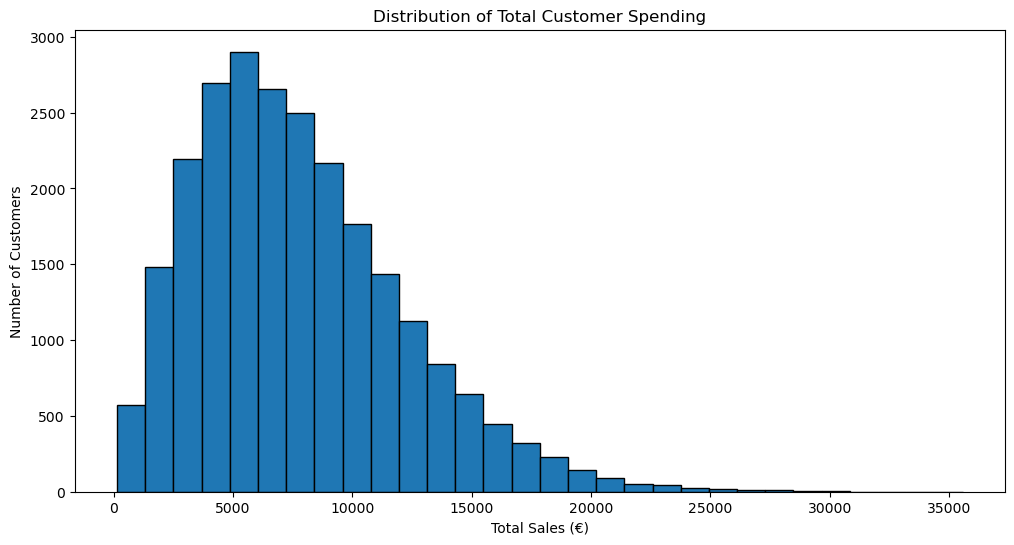

In [90]:
plt.figure(figsize=(12, 6))
plt.hist(data_discount["total_sales"], bins=30, edgecolor="black")
plt.title("Distribution of Total Customer Spending")
plt.xlabel("Total Sales (€)")
plt.ylabel("Number of Customers")
plt.show()

the distribution lead to assume a Gamma distribution due to graph leaning toward the left

In [91]:
from sklearn.preprocessing import StandardScaler
import pymc as pm

columns = ["total_sales", "discount_rate", "frequency", "T"]

data_bayes = data_discount[columns].dropna().copy()
data_bayes = data_bayes[data_bayes["total_sales"] > 0]

predictors = ["discount_rate", "frequency", "T"]

scaler = StandardScaler()

X = scaler.fit_transform(data_bayes[predictors])
y = data_bayes["total_sales"].to_numpy()

y_scaled = y / 1000

coords = {
    "predictor": predictors,
    "customer": np.arange(len(y))
}

with pm.Model(coords=coords) as gamma_model:

    
    X_data = pm.Data(
        "X_data",
        X,
        dims=("customer", "predictor")
    )

    
    intercept = pm.Normal(
        "intercept",
        mu=np.log(y.mean()),
        sigma=1
    )

    
    beta = pm.Normal(
        "beta",
        mu=0,
        sigma=0.5,
        dims="predictor"
    )

    
    alpha = pm.Exponential(
        "alpha",
        lam=1
    )

    
    eta = intercept + pm.math.dot(X_data, beta)

    
    mu = pm.math.exp(eta)

    
    gamma_rate = alpha / mu

    
    spending = pm.Gamma(
        "spending",
        alpha=alpha,
        beta=gamma_rate,
        observed=y,
        dims="customer"
    )

    
    trace = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        target_accept=0.95,
        random_seed=42
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept, beta, alpha]


/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets"
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 10 seconds.


In [92]:
summary = az.summary(
    trace,
    var_names=["intercept", "beta", "alpha"]
)

display(summary)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,8.87436,0.00284,8.9,8.9,5346,3048,1.00,3.9e-05,2.7e-05
beta[discount_rate],0.09324,0.00287,0.089,0.098,5339,2941,1.00,3.9e-05,2.7e-05
beta[frequency],0.40336,0.00325,0.4,0.41,5069,3349,1.00,4.6e-05,3.2e-05
beta[T],0.01597,0.00312,0.011,0.021,4850,3405,1.00,4.5e-05,3.2e-05
alpha,5.203,0.0458,5.1,5.3,5819,2993,1.00,0.0006,0.0004


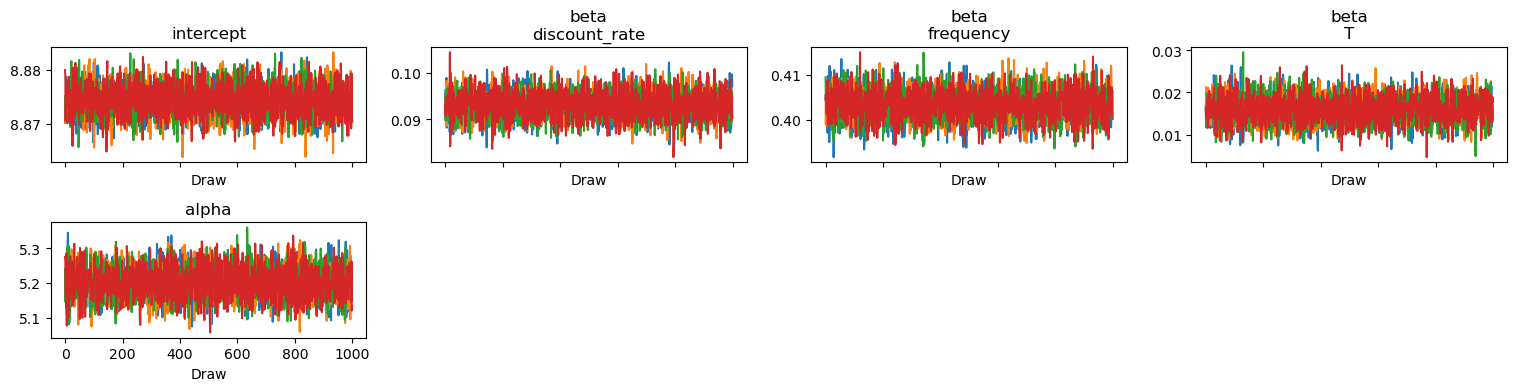

In [93]:
az.plot_trace(
    trace,
    var_names=["intercept", "beta", "alpha"]
)

plt.tight_layout()
plt.show()

In [94]:
beta_samples = trace.posterior["beta"]

percentage_effects = (np.exp(beta_samples) - 1) * 100

effect_summary = pd.DataFrame({
    "Mean (%)": percentage_effects.mean(dim=("chain", "draw")).values,
    "Lower 95%": percentage_effects.quantile(
        0.025, dim=("chain", "draw")
    ).values,
    "Upper 95%": percentage_effects.quantile(
        0.975, dim=("chain", "draw")
    ).values
}, index=predictors)

display(effect_summary)

,Mean (%),Lower 95%,Upper 95%
discount_rate,9.773196,9.160837,10.377594
frequency,49.685213,48.741097,50.652570
T,1.610752,0.989603,2.234229


Discount rate: A one-standard-deviation increase is associated with approximately 9.77% higher expected spending, controlling for frequency and tenure.
Purchase frequency: Shows the strongest association, although this is partly mechanical because more purchases contribute to cumulative spending.
Tenure: Shows a smaller positive association. These intervals indicate high posterior certainty under the fitted model, not proof of causal effects or correct model specification

lets try another Bayesian model this time using a normal distribution

In [95]:
with gamma_model:
    ppc = pm.sample_posterior_predictive(
        trace,
        var_names=["spending"],
        random_seed=42
    )

Sampling: [spending]


/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets"
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

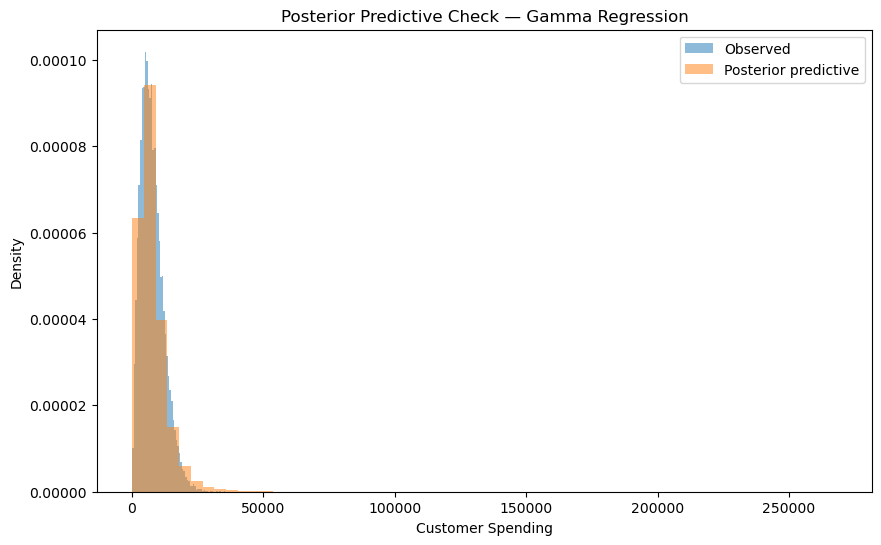

In [96]:
simulated = ppc.posterior_predictive["spending"].values
simulated_flat = simulated.ravel()

plt.figure(figsize=(10, 6))
plt.hist(
    y,
    bins=60,
    density=True,
    alpha=0.5,
    label="Observed"
)

plt.hist(
    simulated_flat,
    bins=60,
    density=True,
    alpha=0.5,
    label="Posterior predictive"
)

plt.xlabel("Customer Spending")
plt.ylabel("Density")
plt.title("Posterior Predictive Check — Gamma Regression")
plt.legend()
plt.show()

In [97]:
observed = y

simulated = (
    ppc.posterior_predictive["spending"]
    .values
    .reshape(-1, len(y))
)

comparison = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Std Dev", "95th Percentile"],
    "Observed": [
        np.mean(observed),
        np.median(observed),
        np.std(observed),
        np.percentile(observed, 95)
    ],
    "Predicted": [
        np.mean(simulated),
        np.median(simulated),
        np.std(simulated),
        np.percentile(simulated, 95)
    ]
})

display(comparison)

,Statistic,Observed,Predicted
0,Mean,7761.636434,7857.565318
1,Median,7086.270000,6490.190969
2,Std Dev,4361.006725,5455.773558
3,95th Percentile,15912.978000,17924.291021


The Gamma model converged successfully and reproduces average spending well, but its predictive distribution is too dispersed.

In [98]:
predictors = ["discount_rate", "frequency", "T"]

df_normal = data_discount[
    ["total_sales"] + predictors
].dropna().copy()

df_normal = df_normal[df_normal["total_sales"] > 0]

X_scaled = StandardScaler().fit_transform(df_normal[predictors])

y = df_normal["total_sales"].to_numpy()
y_scaled = (y - y.mean()) / y.std()


X_shared = X_scaled
y_shared = y_scaled

with pm.Model() as beyesian_model:
    intercept = pm.Normal('Intercept', mu=0, sigma=1)
    
    beta_discount = pm.Normal("discount_rate", mu=0, sigma=0.5)
    beta_frequency = pm.Normal("frequency", mu=0, sigma=0.5)
    beta_T = pm.Normal("T", mu=0, sigma=0.5)

    mu = (intercept
    + beta_discount*X_shared[:,0]
    + beta_frequency*X_shared[:,1]
    +beta_T*X_shared[:,2])

    sigma= pm.HalfNormal('sigma', sigma=1)
    y_pred = pm.Normal('y_pred', mu=mu, sigma=sigma, observed=y_shared)

    trace = pm.sample(2000, chains=4, tune=1000, target_accept=0.9)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [Intercept, discount_rate, frequency, T, sigma]


/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets"
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 2 seconds.


In [99]:
summary_normal = az.summary(
    trace,
    var_names=[
        "Intercept",
        "discount_rate",
        "frequency",
        "T",
        "sigma"
    ]
)

display(summary_normal)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
Intercept,-2e-05,0.00441,-0.0071,0.0071,9828,6048,1.00,4.5e-05,3.1e-05
discount_rate,0.14367,0.00451,0.14,0.15,8666,6191,1.00,4.8e-05,3.5e-05
frequency,0.703,0.00484,0.7,0.71,8763,6328,1.00,5.2e-05,3.6e-05
T,-0.00377,0.00465,-0.011,0.0037,8721,6762,1.00,5e-05,3.5e-05
sigma,0.69534,0.00315,0.69,0.7,9585,6238,1.00,3.2e-05,2.3e-05


In [100]:
with beyesian_model:
    ppc_normal = pm.sample_posterior_predictive(
        trace,
        var_names=["y_pred"],
        random_seed=42
    )

Sampling: [y_pred]


/opt/anaconda3/envs/pymc-marketing/lib/python3.12/site-packages/rich/live.py:260: UserWarning: install "ipywidgets"
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

In [101]:
simulated_normal = (
    ppc_normal.posterior_predictive["y_pred"]
    .values.ravel()
)


predicted_euros = simulated_normal * y.std() + y.mean()
observed_euros = y

comparison_normal = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Std Dev", "95th Percentile"],
    "Observed": [
        np.mean(observed_euros),
        np.median(observed_euros),
        np.std(observed_euros),
        np.percentile(observed_euros, 95)
    ],
    "Predicted": [
        np.mean(predicted_euros),
        np.median(predicted_euros),
        np.std(predicted_euros),
        np.percentile(predicted_euros, 95)
    ]
})

display(comparison_normal)

print(
    "Negative predictions:",
    round((predicted_euros < 0).mean() * 100, 2),
    "%"
)

,Statistic,Observed,Predicted
0,Mean,7761.636434,7761.792580
1,Median,7086.270000,7626.175902
2,Std Dev,4361.006725,4361.512666
3,95th Percentile,15912.978000,15152.362304


Negative predictions: 3.15 %


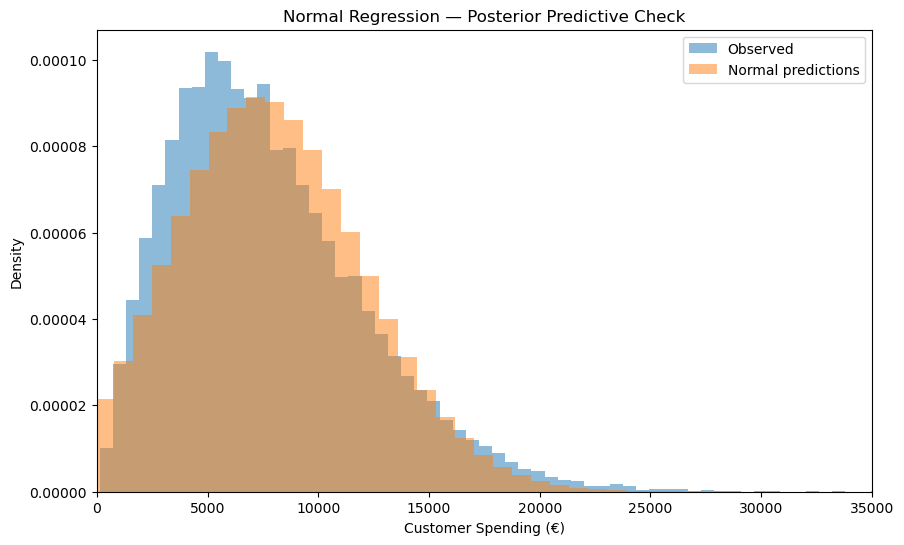

In [102]:
plt.figure(figsize=(10, 6))

plt.hist(
    observed_euros,
    bins=60,
    density=True,
    alpha=0.5,
    label="Observed"
)

plt.hist(
    predicted_euros,
    bins=60,
    density=True,
    alpha=0.5,
    label="Normal predictions"
)

plt.xlim(0, 35000)
plt.xlabel("Customer Spending (€)")
plt.ylabel("Density")
plt.title("Normal Regression — Posterior Predictive Check")
plt.legend()
plt.show()

The Normal model reproduces the mean and standard deviation almost exactly, and its median and 95th percentile are closer to the observed values than Gamma's. However, the plot shows that the Normal model smooths over the observed peak and does not fully reproduce the right tail, beside but generates 3.15% negative spending predictions.The Gamma model captures the positive, right-skewed structure but generates too much variation

<span style="color:blue; font-size:14px; font-weight:bold;">
Due to the absence of information on marketing spending product information we were unable to perform
a Marketing Mix Modelling or a Budget optimization with scenarios
</span>

<span style="color:purple; font-size:16px; font-weight:bold;">
The decline in gross revenue was primarily attributable to lower average order value, rather than a substantial reduction in active customers or purchasing frequency. Customer inactivity, discounts, returns, and customer experience did not independently establish a cause of the decline.
The decomposition identifies where the revenue change occurred, not why transaction values fell. Potential mechanisms such as product mix, quantities purchased, and pricing remain unverified. The principal business implication is to investigate the decline in spend per order before attributing the revenue trend to churn or customer acquisition
</span>